This code is authored by Mizal Kodakkadan

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
import matplotlib.pyplot as plt
from collections import Counter
from collections import defaultdict
from time import time

### The bipartite and its projections

In [2]:
df = pd.read_csv('edges_6.0.csv')
B = nx.from_pandas_edgelist(df, source='Source', target='Target')

recipes = set(df['Source'])
ingredients = set(df['Target'])

for n in recipes:
    B.nodes[n]['bipartite'] = 0
for n in ingredients:
    B.nodes[n]['bipartite'] = 1

R = bipartite.weighted_projected_graph(B, recipes)
I = bipartite.weighted_projected_graph(B, ingredients)

### Pearson coefficient and knn for unweighted projections

Defining Pearson coefficient

In [3]:
def pearson_coeff(G):

    n = nx.number_of_nodes(G)
    deg_count = Counter(y for x,y in nx.degree(G))

    # Initializing the correlation matrix
    deg_pairs = list(nx.node_degree_xy(G))
    dp_counts = Counter(deg_pairs)

    k_max = max(max(x,y) for x,y in deg_pairs)
    e = np.zeros((k_max+1,k_max+1))
    for j in range(k_max+1):
        for k in range(k_max+1):
            e[j][k] = dp_counts[(j,k)] / len(deg_pairs)

    # q_k: prob landing on a node of degree k
    q = {}
    meank = sum(k*deg_count[k] for k in range(k_max+1)) / n
    for k in range(k_max+1):
        p = deg_count[k] / n
        q[k] = k*p/meank

    # evaluating r:
    num = []
    for j in range(k_max+1):
        for k in range(k_max+1):
            num.append(j*k*(e[j][k] - q[j]*q[k]))
    num = sum(num)

    den1 = sum((k**2)*q[k] for k in range(k_max+1))
    sqrt_den2 = sum(k*q[k] for k in range(k_max+1))
    den = den1 - (sqrt_den2 ** 2)
    r = num/den

    return r

Defining knn

In [4]:
def knn(G):

    deg = dict(G.degree())

    knn_i = defaultdict(list)
    for i in G.nodes():
        ki = deg[i]
        if ki != 0:
            ni = G.neighbors(i)
            ki_sum = sum(deg[j] for j in ni)
            knn_i[ki].append(ki_sum / ki)
    knn_i = dict(sorted(knn_i.items()))

    knn_k = {k: np.mean(val) for k,val in knn_i.items()}

    return knn_k

def neutral_knn(G):
    k = np.array([y for x,y in G.degree()])
    return np.sum(k**2)/np.sum(k)

Processes:

In [5]:
print('For recipes, r = ',pearson_coeff(R))
print('For ingredients, r = ',pearson_coeff(I))

For recipes, r =  0.06650281761245071
For ingredients, r =  -0.4458020107355449


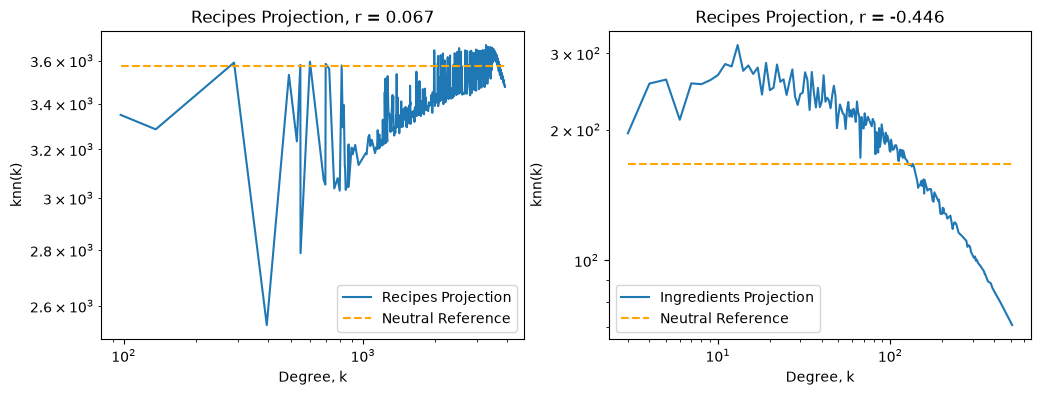

In [21]:
xruw = knn(R).keys()
yruw = knn(R).values()
nruw = neutral_knn(R)
xiuw = knn(I).keys()
yiuw = knn(I).values()
niuw = neutral_knn(I)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.loglog(xruw,yruw, label='Recipes Projection')
plt.hlines(nruw, xmin=min(xruw),xmax=max(xruw), linestyles='--', label='Neutral Reference', color='orange')
plt.xlabel('Degree, k')
plt.ylabel('knn(k)')
plt.legend()
plt.title(f'Recipes Projection, r = {pearson_coeff(R):.3f}')

plt.subplot(1,2,2)
plt.loglog(xiuw,yiuw, label='Ingredients Projection')
plt.hlines(niuw, xmin=min(xiuw),xmax=max(xiuw), linestyles='--', label='Neutral Reference', color='orange')
plt.xlabel('Degree, k')
plt.ylabel('knn(k)')
plt.legend()
plt.title(f'Recipes Projection, r = {pearson_coeff(I):.3f}')

plt.savefig('save.png')
plt.show()

In [7]:
print(I['salt']['sugar']['weight'])

372


In [8]:
print(I.size(weight='weight'))

288588.0


### Weighted Pearson Coefficient Function:

In [9]:
def weighted_pearson_coeff(G):

    # Correlation Matrix
    total_weight = G.size(weight='weight')
    weighted_dp_counts = Counter()
    for i, j, w in G.edges(data=True):
        dp = tuple(sorted((G.degree(i), G.degree(j))))
        weighted_dp_counts[dp] += w['weight']

    k_max = max(max(x,y) for x,y in weighted_dp_counts)
    e = np.zeros((k_max+1,k_max+1))
    for (j,k) , count in weighted_dp_counts.items():
        prob = count / total_weight
        e[j][k] = prob
        e[k][j] = prob

    # q_k: prob of landing on a node of degree, 'k'
    deg = dict(I.degree(weight='weight'))
    deg_count = Counter(k for k in deg.values())
    mean_k = np.mean(list(deg.values()))
    
    q = {}
    for k in deg_count:
        p = deg_count[k] / I.number_of_nodes()
        q[k] = k*p / mean_k

    # evaluating r:

    num = []
    for (j,k) in weighted_dp_counts:
        num.append(j*k*(e[j][k] - q.get(j,0)*q.get(k,0)))
    num = sum(num)
    
    den1 = sum((k**2)*q[k] for k in deg_count)
    sqrt_den2 = sum(k*q[k] for k in deg_count)
    den = den1 - (sqrt_den2 ** 2)
    r = num/den

    return r

In [10]:
print('For recipes, r = ', weighted_pearson_coeff(R))
print('For ingredients, r = ', weighted_pearson_coeff(I))

For recipes, r =  0.12409967390882516
For ingredients, r =  0.000839205146294763


Weighted knn:

In [11]:
def weighted_knn(G):
    deg = dict(G.degree(weight='weight'))
    
    knn_i = defaultdict(list)
    for i in sorted(G.nodes()):
    
        ki = deg[i]
        if ki != 0:
            ni = G.neighbors(i)
            ki_sum = sum(deg.get(j,0) for j in ni)
            knn_i[ki].append(ki_sum / ki)
    
    knn_i = dict(sorted(knn_i.items()))
    knn_k = {k: np.mean(val) for k,val in knn_i.items()}
    
    return(knn_k)

In [12]:
def weighted_neutral_knn(G):
    k = np.array([y for y in dict(G.degree(weight='weight')).values()])
    return np.sum(k**2)/np.sum(k)

Plotting:

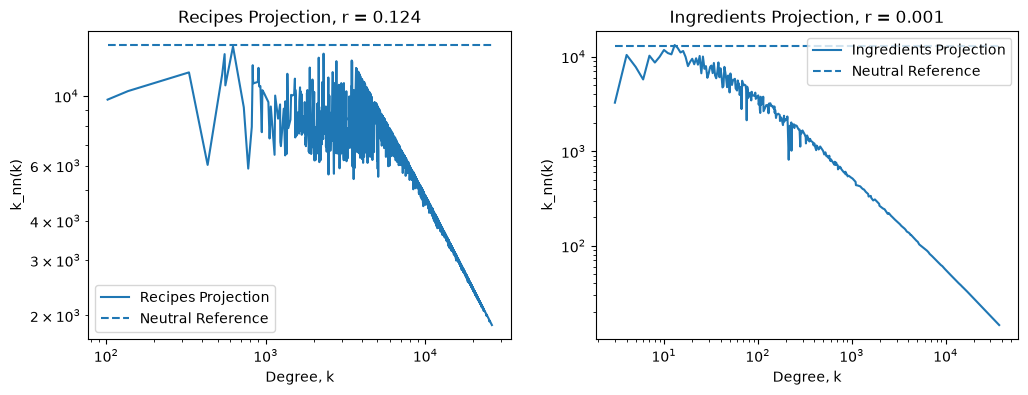

In [22]:
xr = list(weighted_knn(R).keys())
yr = list(weighted_knn(R).values())
nr = weighted_neutral_knn(R)
xi = list(weighted_knn(I).keys())
yi = list(weighted_knn(I).values())
ni = weighted_neutral_knn(I)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.loglog(xr,yr, label='Recipes Projection')
plt.hlines(nr, xmin=min(xr),xmax=max(xr), linestyles='--', label='Neutral Reference')
plt.xlabel('Degree, k')
plt.ylabel('k_nn(k)')
plt.legend()
plt.title(f'Recipes Projection, r = {weighted_pearson_coeff(R):.3f}')

plt.subplot(1,2,2)
plt.loglog(xi,yi, label='Ingredients Projection')
plt.hlines(ni, xmin=min(xi),xmax=max(xi), linestyles='--', label='Neutral Reference')
plt.xlabel('Degree, k')
plt.ylabel('k_nn(k)')
plt.legend()
plt.title(f'Ingredients Projection, r = {weighted_pearson_coeff(I):.3f}')

plt.savefig('save2.png')
plt.show()

### Fitting the graph to find μ

In [14]:
logxr = np.log10(xr)
logyr = np.log10(yr)
logxi = np.log10(xi)
logyi = np.log10(yi)

mr, cr = np.polyfit(logxr,logyr,1)
mi, ci = np.polyfit(logxi,logyi,1)

fit_r = 10**(mr*logxr + cr)
fit_i = 10**(mi*logxi + ci)

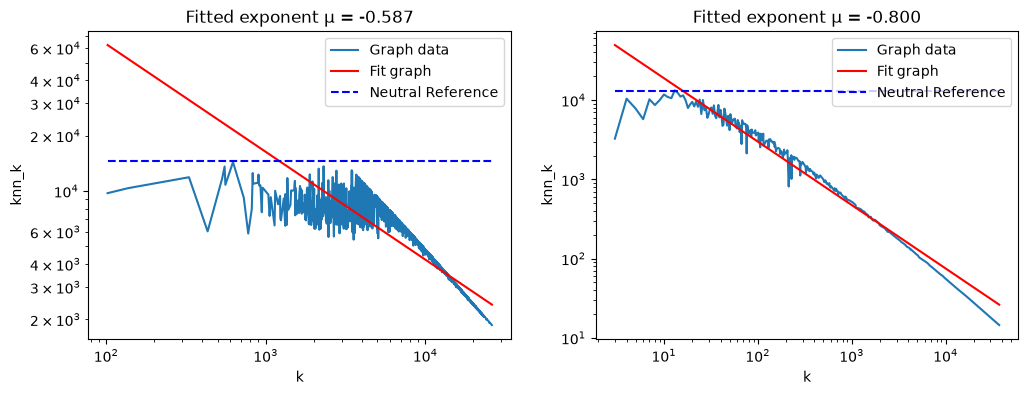

In [15]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.loglog(xr, yr, label = 'Graph data')
plt.plot(xr, fit_r, label = 'Fit graph', color='red')
plt.hlines(nr, xmin=min(xr), xmax=max(xr), linestyles='--', color='blue',label='Neutral Reference')
plt.xlabel('k')
plt.ylabel('knn_k')
plt.legend()
plt.title(f'Fitted exponent μ = {mr:.3f}')

plt.subplot(1,2,2)
plt.loglog(xi, yi, label = 'Graph data')
plt.plot(xi, fit_i, label = 'Fit graph', color='red')
plt.hlines(ni, xmin=min(xi), xmax=max(xi), linestyles='--', color='blue',label='Neutral Reference')
plt.xlabel('k')
plt.ylabel('knn_k')
plt.legend()
plt.title(f'Fitted exponent μ = {mi:.3f}')

plt.show()

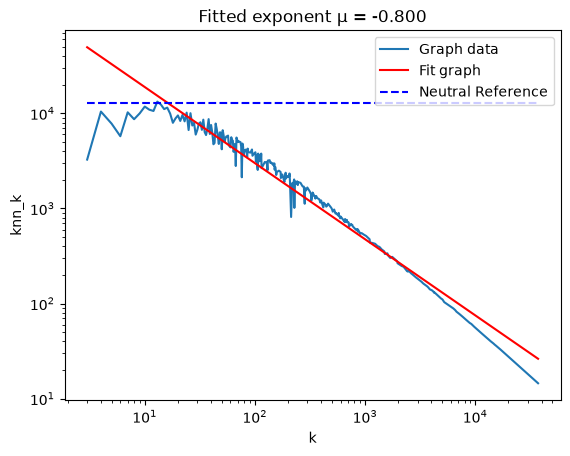

In [23]:
plt.figure()
plt.loglog(xi, yi, label = 'Graph data')
plt.plot(xi, fit_i, label = 'Fit graph', color='red')
plt.hlines(ni, xmin=min(xi), xmax=max(xi), linestyles='--', color='blue',label='Neutral Reference')
plt.xlabel('k')
plt.ylabel('knn_k')
plt.legend()
plt.title(f'Fitted exponent μ = {mi:.3f}')

plt.savefig('save3.png')
plt.show()